# Brasil em Dados

## Redes neurais artificiais

Este notebook aplica uma rede neural artificial do tipo MLP
(Perceptron Multicamadas) para classificar municípios com IDEB acima da
mediana do conjunto de treino.

Serão utilizadas as mesmas variáveis preditoras, o mesmo limiar e a
mesma divisão treino/teste do notebook de aprendizado de máquina. Assim,
os resultados poderão ser comparados.

A classificação é exploratória e não representa uma classificação
oficial de qualidade educacional.

## 1. Carregamento e preparação dos dados

Serão usadas como variáveis preditoras o logaritmo da população municipal
e o rendimento domiciliar per capita. O IDEB será utilizado como
variável-alvo e transformado em duas classes pelo mesmo critério adotado
no notebook anterior.

A mediana será calculada apenas no conjunto de treino. A padronização das
variáveis preditoras será feita dentro de um `Pipeline`, para que, em
cada etapa da validação cruzada, o padronizador seja ajustado somente
com os dados de treino daquela etapa.

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

PROJECT_ROOT = Path("..")
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

arquivo_base = DATA_PROCESSED / "brasil_em_dados_municipios.csv"

df_integrado = pd.read_csv(
    arquivo_base,
    encoding="utf-8-sig",
    dtype={"codigo_municipio": "Int64"}
)

colunas_modelo = [
    "codigo_municipio",
    "municipio",
    "populacao_2022",
    "renda_domiciliar_per_capita_2022",
    "ideb_2023"
]

df_modelo = df_integrado[colunas_modelo].copy()

for coluna in [
    "populacao_2022",
    "renda_domiciliar_per_capita_2022",
    "ideb_2023"
]:
    df_modelo[coluna] = pd.to_numeric(
        df_modelo[coluna],
        errors="coerce"
    )

df_modelo = df_modelo.dropna(
    subset=[
        "populacao_2022",
        "renda_domiciliar_per_capita_2022",
        "ideb_2023"
    ]
).copy()

df_modelo["log_populacao_2022"] = np.log1p(
    df_modelo["populacao_2022"]
)

variaveis_preditora = [
    "log_populacao_2022",
    "renda_domiciliar_per_capita_2022"
]

X = df_modelo[variaveis_preditora]
y_continuo = df_modelo["ideb_2023"]

X_treino, X_teste, y_treino_continuo, y_teste_continuo = train_test_split(
    X,
    y_continuo,
    test_size=0.20,
    random_state=42
)

limiar_ideb = y_treino_continuo.median()

y_treino = (
    y_treino_continuo > limiar_ideb
).astype(int)

y_teste = (
    y_teste_continuo > limiar_ideb
).astype(int)

print("Municípios utilizados:", len(df_modelo))
print(f"Limiar calculado no treino: IDEB > {limiar_ideb:.2f}")
print("Dimensões de X_treino:", X_treino.shape)
print("Dimensões de X_teste:", X_teste.shape)

Municípios utilizados: 5382
Limiar calculado no treino: IDEB > 4.80
Dimensões de X_treino: (4305, 2)
Dimensões de X_teste: (1077, 2)


## 2. Construção e ajuste da rede neural

A rede recebe duas variáveis na camada de entrada e aprende padrões por
meio de uma ou mais camadas ocultas. A camada de saída estima as classes
definidas pelo limiar do IDEB.

Serão testadas arquiteturas pequenas e diferentes níveis de
regularização. O `GridSearchCV` escolherá a configuração com melhor F1
médio na validação cruzada do conjunto de treino.

In [8]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pipeline_mlp = Pipeline([
    ("padronizador", StandardScaler()),
    ("rede", MLPClassifier(
        random_state=42,
        max_iter=2000,
        early_stopping=True,
        n_iter_no_change=30
    ))
])

grade_mlp = {
    "rede__hidden_layer_sizes": [
        (4,),
        (8,),
        (16,),
        (8, 4)
    ],
    "rede__alpha": [
        0.0001,
        0.001,
        0.01
    ]
}

busca_mlp = GridSearchCV(
    estimator=pipeline_mlp,
    param_grid=grade_mlp,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

busca_mlp.fit(X_treino, y_treino)

print("Melhores parâmetros:", busca_mlp.best_params_)
print(f"F1 médio na validação cruzada: {busca_mlp.best_score_:.3f}")

rede_final = busca_mlp.best_estimator_
rede_treinada = rede_final.named_steps["rede"]

print("Épocas executadas:", rede_treinada.n_iter_)

Melhores parâmetros: {'rede__alpha': 0.0001, 'rede__hidden_layer_sizes': (4,)}
F1 médio na validação cruzada: 0.703
Épocas executadas: 150


## 3. Avaliação no conjunto de teste

Após a seleção dos hiperparâmetros por validação cruzada, a rede será
avaliada no conjunto de teste. As métricas serão as mesmas usadas no
notebook anterior: acurácia, precisão, recall, F1 e AUC.

In [9]:
previsoes_mlp = rede_final.predict(X_teste)
probabilidades_mlp = rede_final.predict_proba(X_teste)[:, 1]

resultados_mlp = pd.DataFrame([{
    "modelo": "Rede neural MLP",
    "acuracia": accuracy_score(y_teste, previsoes_mlp),
    "precisao": precision_score(
        y_teste,
        previsoes_mlp,
        zero_division=0
    ),
    "recall": recall_score(
        y_teste,
        previsoes_mlp,
        zero_division=0
    ),
    "f1": f1_score(
        y_teste,
        previsoes_mlp,
        zero_division=0
    ),
    "auc": roc_auc_score(
        y_teste,
        probabilidades_mlp
    )
}])

display(resultados_mlp.round(3))

,modelo,acuracia,precisao,recall,f1,auc
0,Rede neural MLP,0.71,0.679,0.72,0.699,0.746


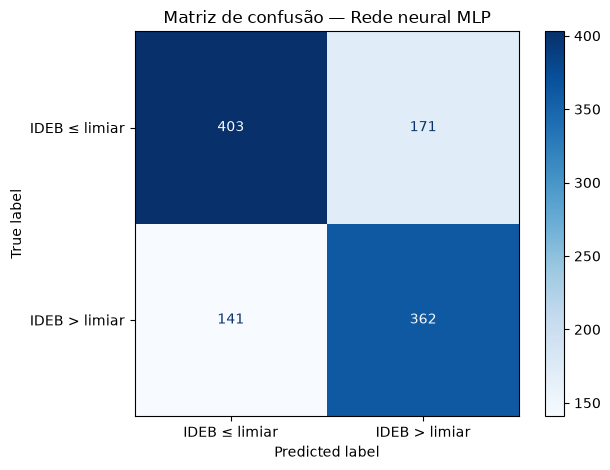

In [10]:
ConfusionMatrixDisplay.from_estimator(
    rede_final,
    X_teste,
    y_teste,
    display_labels=[
        "IDEB ≤ limiar",
        "IDEB > limiar"
    ],
    cmap="Blues"
)

plt.title("Matriz de confusão — Rede neural MLP")
plt.tight_layout()
plt.show()

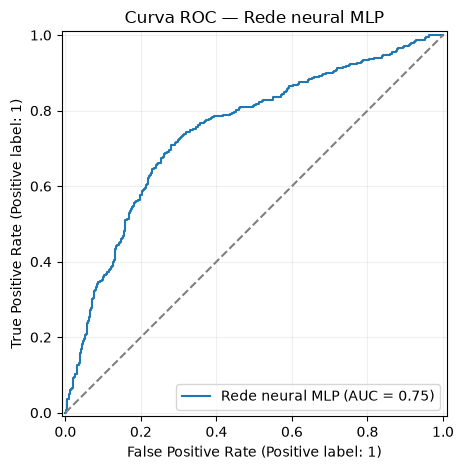

In [11]:
RocCurveDisplay.from_estimator(
    rede_final,
    X_teste,
    y_teste,
    name="Rede neural MLP"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Classificador aleatório"
)

plt.title("Curva ROC — Rede neural MLP")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4. Comparação com os modelos clássicos

A tabela salva pelo notebook `04_aprendizado_de_maquina.ipynb` será
combinada com o resultado da rede neural. Como a divisão treino/teste é
reproduzida com a mesma semente e as mesmas observações, as métricas
podem ser comparadas.

A comparação deve considerar mais de uma métrica, e não somente a
acurácia.

In [12]:
arquivo_resultados_classicos = (
    DATA_PROCESSED / "resultados_modelos_classicos.csv"
)

if arquivo_resultados_classicos.exists():
    resultados_classicos = pd.read_csv(
        arquivo_resultados_classicos,
        encoding="utf-8-sig"
    )

    comparacao_modelos = pd.concat(
        [resultados_classicos, resultados_mlp],
        ignore_index=True
    )

    display(
        comparacao_modelos
        .sort_values("f1", ascending=False)
        .reset_index(drop=True)
        .round(3)
    )
else:
    print(
        "Arquivo dos resultados clássicos não encontrado. "
        "Execute a célula de salvamento no notebook 04 e rode esta célula novamente."
    )

,modelo,acuracia,precisao,recall,f1,auc
0,Árvore de decisão,0.708,0.665,0.755,0.708,0.733
1,Rede neural MLP,0.710,0.679,0.720,0.699,0.746
2,Gradient Boosting,0.711,0.693,0.686,0.689,0.737
3,Random Forest,0.705,0.679,0.698,0.688,0.739
4,KNN,0.700,0.680,0.676,0.678,0.727
5,Referência,0.533,0.000,0.000,0.000,0.500


## 5. Síntese e limitações

A rede neural MLP obteve F1 médio de 0,703 na validação cruzada e F1
de 0,699 no conjunto de teste. Entre os modelos avaliados, apresentou a
maior AUC no teste (0,746), mas não teve o maior F1 nem a maior acurácia.
A árvore de decisão obteve o maior F1 no teste (0,708), enquanto o
Gradient Boosting apresentou a maior acurácia (0,711).

Assim, os resultados não apontam um único modelo como superior em todas
as métricas. A escolha depende do aspecto priorizado. A MLP demonstrou
capacidade moderada de ordenação das classes pela AUC, mas seu F1 no teste
ficou abaixo do obtido pela árvore de decisão.

A rede utiliza somente o logaritmo da população e o rendimento
domiciliar per capita. Portanto, seu desempenho mede a capacidade dessas
duas variáveis de distinguir municípios acima e abaixo do limiar adotado;
não representa uma explicação completa do IDEB nem demonstra causalidade.

O MLP não fornece diretamente uma importância das variáveis como as
árvores. Além disso, transformar o IDEB em duas classes perde
informação sobre as diferenças numéricas entre os municípios. Como a
divisão entre treino e teste foi aleatória, a avaliação também não mede
especificamente o desempenho em regiões inteiramente novas.